# DR02 — Pixel-space DDPM architecture

## 1. Objective and scope

DR02 defines and validates the unconditional pixel-space DDPM core for $32\times32$ RGB avatars. It freezes the mathematical primitives, Tiny U-Net V1, correctness gates, and engineering evidence needed before a full training protocol. It is not a training notebook and does not select a schedule winner, final batch size, optimizer, learning rate, training duration, or dataset scale.

In [1]:
from __future__ import annotations

import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch


def find_project_root() -> Path:
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (candidate / 'src' / 'tiny_avatar_diffusion').is_dir():
            return candidate
    raise RuntimeError('Run this notebook from the repository root or notebooks directory.')


ROOT = find_project_root()
sys.path.insert(0, str(ROOT / 'src'))

from tiny_avatar_diffusion.diffusion import CosineDDPMSchedule, LinearDDPMSchedule
from tiny_avatar_diffusion.unet import TinyUNet

TINY_OVERFIT_DIR = ROOT / 'reports' / 'dr02_tiny_overfit_debug' / 'rtx4060_2000'
FP32_PROFILE_DIR = ROOT / 'reports' / 'dr02_gpu_profile' / 'fp32_training'
AMP_PROFILE_DIR = ROOT / 'reports' / 'dr02_gpu_profile' / 'amp_parity'
SAMPLING_PROFILE_DIR = ROOT / 'reports' / 'dr02_gpu_profile' / 'ancestral_sampling'

print('Project root located through relative discovery.')
print(f'PyTorch: {torch.__version__}; CUDA available: {torch.cuda.is_available()}')

Project root located through relative discovery.
PyTorch: 2.5.1+cu121; CUDA available: True


## 2. Frozen input contract from DR01

DR01 supplies deterministic manifests and archive-backed source-image references. The DR02 debug runner consumed the `10k` **TRAIN** manifest, composited native RGBA images on white, converted them to RGB, resized them to $32\times32$, and mapped pixels to float32 $[-1,1]$. The diffusion input contract is batch-first `[B, 3, 32, 32]`. DR02 remains unconditional: no tokenizer, text encoder, cross-attention, or classifier-free guidance is implemented here.

## 3. DDPM formulation

For $t=1,\ldots,T$, with Python indices `0,…,T-1` representing those mathematical steps:

$$\alpha_t=1-\beta_t,\qquad \bar\alpha_t=\prod_{s=1}^{t}\alpha_s.$$

The forward process is

$$q(x_t\mid x_0)=\mathcal N(\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I),\qquad x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon.$$

Tiny U-Net predicts $\epsilon_\theta(x_t,t)$ and is trained with unweighted MSE against $\epsilon$. The reconstructed clean sample is

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta}{\sqrt{\bar\alpha_t}}.$$

The V1 fixed-small posterior variance is

$$\tilde\beta_t=\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t,$$

with posterior mean

$$\tilde\mu_t(x_t,x_0)=c_{1,t}x_0+c_{2,t}x_t,$$

$$c_{1,t}=\frac{\sqrt{\bar\alpha_{t-1}}\beta_t}{1-\bar\alpha_t},\qquad c_{2,t}=\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}.$$

During sampling, $x_0$ is replaced by reconstructed $\hat x_0$, optionally clamped to $[-1,1]$ when `clip_denoised=True`. The ancestral step is

$$x_{t-1}=\tilde\mu_t+\mathbf 1_{t>0}\sqrt{\tilde\beta_t}z,\qquad z\sim\mathcal N(0,I).$$

The final Python index `t=0` is the first noisy mathematical step; it has no reverse noise contribution. The reusable implementation lives in `src/tiny_avatar_diffusion/diffusion.py`, rather than being duplicated in this notebook.

## 4. Noise schedules

Two fixed $T=1000$ schedule arms are available: the original linear $\beta$ schedule ($10^{-4}\rightarrow0.02$) and the canonical cosine construction with offset $s=0.008$ and `max_beta=0.999`. They share all subsequent forward and reverse DDPM mathematics. Linear is the validated reference arm; cosine is the validated focused ablation arm. The schedule winner remains open until empirical comparison.

linear beta[0]=0.00010000, beta[500]=0.01005996, beta[-1]=0.02000000; alpha_bar[0]=0.99989998, alpha_bar[500]=0.07779666, alpha_bar[-1]=0.00004036
cosine beta[0]=0.00004128, beta[500]=0.00315569, beta[-1]=0.99900001; alpha_bar[0]=0.99995869, alpha_bar[500]=0.49228504, alpha_bar[-1]=0.00000000


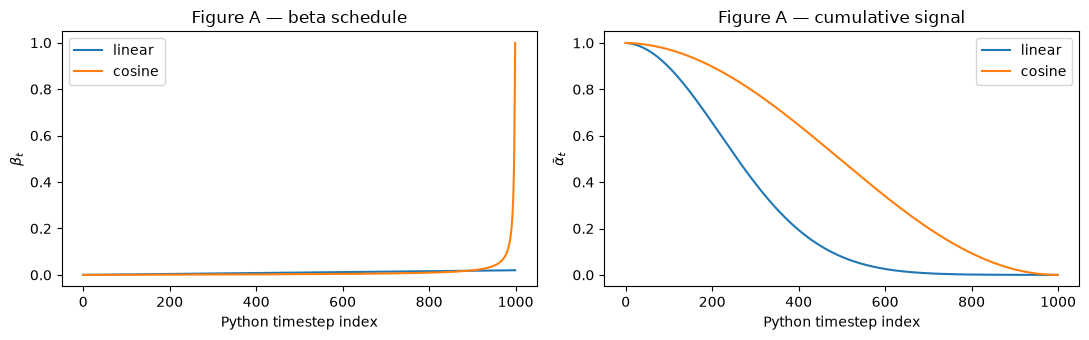

In [2]:
linear = LinearDDPMSchedule()
cosine = CosineDDPMSchedule()
for name, schedule in [('linear', linear), ('cosine', cosine)]:
    print(
        f'{name:6s} beta[0]={schedule.betas[0]:.8f}, '
        f'beta[500]={schedule.betas[500]:.8f}, beta[-1]={schedule.betas[-1]:.8f}; '
        f'alpha_bar[0]={schedule.alphas_cumprod[0]:.8f}, '
        f'alpha_bar[500]={schedule.alphas_cumprod[500]:.8f}, '
        f'alpha_bar[-1]={schedule.alphas_cumprod[-1]:.8f}'
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
steps = torch.arange(linear.betas.numel())
axes[0].plot(steps, linear.betas, label='linear')
axes[0].plot(steps, cosine.betas, label='cosine')
axes[0].set(title='Figure A — beta schedule', xlabel='Python timestep index', ylabel=r'$\beta_t$')
axes[0].legend()
axes[1].plot(steps, linear.alphas_cumprod, label='linear')
axes[1].plot(steps, cosine.alphas_cumprod, label='cosine')
axes[1].set(title='Figure A — cumulative signal', xlabel='Python timestep index', ylabel=r'$\bar\alpha_t$')
axes[1].legend()
fig.tight_layout()
plt.show()

## 5. Frozen Tiny U-Net V1

The unconditional epsilon predictor has spatial path $32\rightarrow16\rightarrow8$, base width 64, and bottleneck width 128. The encoder channel pattern is `64 → 128 → 128`; the decoder uses concatenated skip tensors with input widths `256, 256, 192`, returning through `128, 128, 64`. Each encoder and decoder spatial level contains two time-conditioned ResBlocks, and the bottleneck contains two ResBlocks. The blocks use GroupNorm (32 groups), SiLU, and skip connections. Timesteps use a sinusoidal 64-dimensional embedding followed by a `64 → 256 → 256` MLP. Downsampling is stride-2 convolution; upsampling is nearest-neighbor ×2 followed by convolution. The final convolution projects to 3 channels with no output activation, so epsilon prediction remains unbounded. There is no visual self-attention.

In [3]:
torch.manual_seed(2026)
model = TinyUNet(dropout=0.0)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f'TinyUNet V1 parameters: {parameter_count:,}')
print('Spatial bottleneck: 8x8; bottleneck channels: 128')

TinyUNet V1 parameters: 4,595,779
Spatial bottleneck: 8x8; bottleneck channels: 128


## 6. Mathematical and implementation correctness gates

The DR02 test suite covers schedule construction, coefficient identities, timestep indexing, extraction/broadcasting, `q_sample`, $x_0$ reconstruction, posterior mean/variance, final-step noise masking, ancestral reverse sampling, and Tiny U-Net integration. Schedules are buffers rather than trainable parameters; they move with the module. The following CPU demonstration imports the real implementations and checks a deterministic forward/reconstruction round trip.

In [4]:
x0 = torch.linspace(-1.0, 1.0, 2 * 3 * 4 * 4, dtype=torch.float32).reshape(2, 3, 4, 4)
epsilon = torch.linspace(0.75, -0.75, x0.numel(), dtype=torch.float32).reshape_as(x0)
timesteps = torch.tensor([0, 500], dtype=torch.long)
x_t = linear.q_sample(x0, timesteps, epsilon)
reconstructed_x0 = linear.predict_x_start_from_noise(x_t, timesteps, epsilon)
print('q_sample shape:', tuple(x_t.shape))
print('max round-trip absolute error:', float((reconstructed_x0 - x0).abs().max()))
assert torch.allclose(reconstructed_x0, x0, atol=1e-5, rtol=1e-5)

# Deliberately construct an out-of-range reconstructed x0 without a model call.
diagnostic_x_t = torch.zeros(1, 1, 1, 3)
diagnostic_t = torch.tensor([500], dtype=torch.long)
desired_x0 = torch.tensor([[[[-2.0, 0.25, 2.0]]]])
predicted_epsilon = (
    -desired_x0 * linear.sqrt_alphas_cumprod[500] / linear.sqrt_one_minus_alphas_cumprod[500]
)
unclipped = linear.p_mean_variance_from_noise(
    diagnostic_x_t, diagnostic_t, predicted_epsilon, clip_denoised=False
)
clipped = linear.p_mean_variance_from_noise(
    diagnostic_x_t, diagnostic_t, predicted_epsilon, clip_denoised=True
)
print('unclipped reconstructed x0:', unclipped['predicted_x_start'].flatten().tolist())
print('clipped reconstructed x0:  ', clipped['predicted_x_start'].flatten().tolist())
assert torch.equal(clipped['predicted_x_start'], desired_x0.clamp(-1.0, 1.0))

q_sample shape: (2, 3, 4, 4)
max round-trip absolute error: 5.960464477539063e-08
unclipped reconstructed x0: [-2.0, 0.25, 2.0]
clipped reconstructed x0:   [-1.0, 0.25, 1.0]


## 7. Tiny-subset overfit gate

**DEBUG / CORRECTNESS ONLY.** The canonical 2000-step run used 16 deterministic `10k` TRAIN images (seed 2026), batch 8, Tiny U-Net dropout 0, linear $T=1000$, epsilon MSE, AdamW (`lr=1e-4`, weight decay 0), and FP32. These settings demonstrate the ability to fit a tiny subset; they are not a final training protocol. The fixed probe evaluated timesteps 0, 250, 500, and 999. Saved previews exist for the untrained and trained debug model; they are qualitative debug artifacts, not a generative-quality evaluation.

subset size / seed: 16 / 2026
diagnostic steps: 2000
fixed-probe epsilon MSE: 1.1243288417657216 → 0.1392160343627135
fixed-probe reconstructed-x0 MSE: 7063.709879557292 → 23.48373031616211
saved qualitative debug previews: sample_trained.png sample_untrained.png


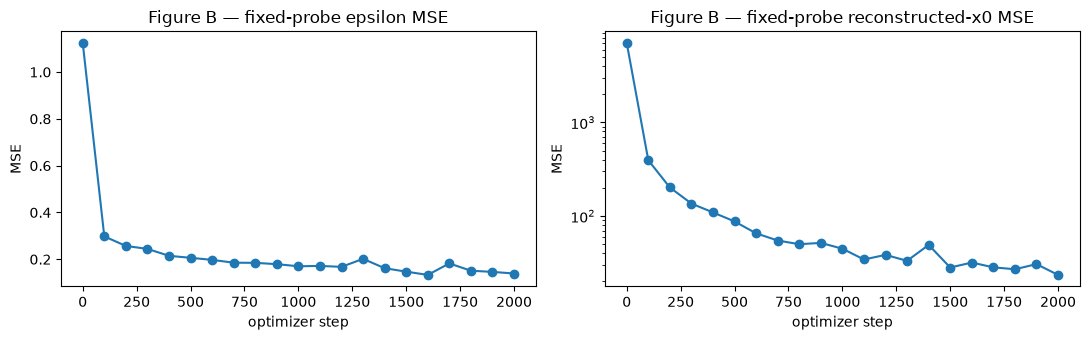

In [5]:
with (TINY_OVERFIT_DIR / 'summary.json').open(encoding='utf-8') as handle:
    tiny_summary = json.load(handle)
with (TINY_OVERFIT_DIR / 'metrics.csv').open(newline='', encoding='utf-8') as handle:
    tiny_metrics = list(csv.DictReader(handle))

print('subset size / seed:', tiny_summary['subset_size'], '/', tiny_summary['subset_seed'])
print('diagnostic steps:', tiny_summary['max_steps'])
print('fixed-probe epsilon MSE:', tiny_summary['initial_probe_epsilon_mse'], '→', tiny_summary['final_probe_epsilon_mse'])
print('fixed-probe reconstructed-x0 MSE:', tiny_summary['initial_probe_x0_mse'], '→', tiny_summary['final_probe_x0_mse'])
print('saved qualitative debug previews:', *(path.name for path in sorted(TINY_OVERFIT_DIR.glob('sample_*.png'))))

metric_steps = [int(row['step']) for row in tiny_metrics]
epsilon_mse = [float(row['probe_epsilon_mse']) for row in tiny_metrics]
x0_mse = [float(row['probe_x0_mse']) for row in tiny_metrics]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(metric_steps, epsilon_mse, marker='o')
axes[0].set(title='Figure B — fixed-probe epsilon MSE', xlabel='optimizer step', ylabel='MSE')
axes[1].plot(metric_steps, x0_mse, marker='o')
axes[1].set(title='Figure B — fixed-probe reconstructed-x0 MSE', xlabel='optimizer step', ylabel='MSE')
axes[1].set_yscale('log')
fig.tight_layout()
plt.show()

## 8. GPU compute evidence

All profiling evidence is compute/memory evidence from the recorded NVIDIA GeForce RTX 4060 Laptop GPU environment, not a quality experiment. Phase 8A FP32 training throughput rose from about 473 images/s at batch 8 to about 909 images/s at batch 32 and remained about 908 images/s at batch 128: the measured curve saturated approximately around B32+. Phase 8B’s B32 AMP-FP16 pilot had healthy parity and a 19.30% throughput gain in that canonical workload. This does not imply AMP is always faster; conditional AMP requires its own short parity sanity check. No final physical batch or universal sampling precision was frozen.

Phase 8A FP32 throughput (images/s): [(8, 472.93), (16, 753.89), (32, 909.04), (64, 807.35), (128, 908.06)]
Phase 8B B32 AMP throughput gain (%): 19.3
Phase 8C sampler: ancestral DDPM ; T = 1000
Phase 8C B1 FP32: 37.025 s/image
Phase 8C B1 AMP_FP16: 22.038 s/image
Phase 8C B32 FP32: 0.733 s/image
Phase 8C B32 AMP_FP16: 0.654 s/image


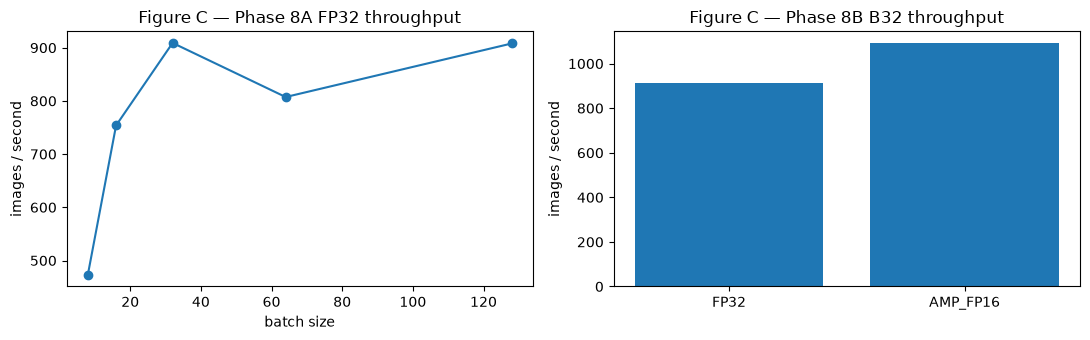

In [6]:
with (FP32_PROFILE_DIR / 'summary.json').open(encoding='utf-8') as handle:
    fp32_summary = json.load(handle)
with (AMP_PROFILE_DIR / 'summary.json').open(encoding='utf-8') as handle:
    amp_summary = json.load(handle)
with (SAMPLING_PROFILE_DIR / 'summary.json').open(encoding='utf-8') as handle:
    sampling_summary = json.load(handle)

fp32_rows = fp32_summary['batch_results']
print('Phase 8A FP32 throughput (images/s):', [(row['batch_size'], round(row['images_per_second'], 2)) for row in fp32_rows])
print('Phase 8B B32 AMP throughput gain (%):', round(amp_summary['comparison']['throughput_gain_percent'], 2))
print('Phase 8C sampler:', sampling_summary['sampler'], '; T =', sampling_summary['diffusion_timesteps'])
for row in sampling_summary['configuration_results']:
    print(f"Phase 8C B{row['batch_size']} {row['precision']}: {row['seconds_per_image']:.3f} s/image")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot([row['batch_size'] for row in fp32_rows], [row['images_per_second'] for row in fp32_rows], marker='o')
axes[0].set(title='Figure C — Phase 8A FP32 throughput', xlabel='batch size', ylabel='images / second')
amp_rows = amp_summary['precision_results']
axes[1].bar([row['precision'] for row in amp_rows], [row['images_per_second'] for row in amp_rows])
axes[1].set(title='Figure C — Phase 8B B32 throughput', ylabel='images / second')
fig.tight_layout()
plt.show()

Phase 8C measured full $T=1000$ ancestral sampling with fixed-small variance and no final-step noise. It is expensive, and batching materially improves per-image throughput: the canonical FP32 observation was 37.025 s/image at B1 versus 0.733 s/image at B32. Absolute and relative B1 timings varied substantially between repetitions and should be treated as hardware/run-specific observations rather than stable universal model characteristics.

## 9. Final sampling policy

The frozen future MAIN sampling policy clips reconstructed $\hat x_0$ to $[-1,1]$ **before** calculating the posterior mean. The low-level reusable API retains `clip_denoised=False` as its default for backwards compatibility with historical correctness and profiling paths; the future MAIN caller must request `clip_denoised=True`. Predicted epsilon remains unclipped, as do $x_t$, Gaussian reverse noise, and the U-Net output.

## 10. Final DR02 decision matrix

| Component | Final DR02 status | Choice | Rationale / handoff |
|---|---|---|---|
| Generative space | FROZEN | Pixel-space DDPM | RGB $32\times32$ DR01 contract |
| Prediction and loss | FROZEN | Epsilon prediction; unweighted MSE | Validated DDPM core |
| Diffusion horizon | FROZEN | $T=1000$; fixed-small variance | Validated schedule and reverse primitives |
| Linear schedule | FROZEN AS REFERENCE ARM | $10^{-4}\rightarrow0.02$ | Validated reference arm |
| Cosine schedule | FROZEN AS FOCUSED ABLATION ARM | Canonical cosine, $s=0.008$ | Validated focused ablation arm |
| Schedule winner | OPEN UNTIL EMPIRICAL COMPARISON | None | Requires matched empirical comparison |
| Sampling | FROZEN | Ancestral DDPM; no noise at final step | Fixed-small reverse process |
| Reconstructed $x_0$ | FROZEN | Clamp to $[-1,1]$ for future MAIN sampling | Epsilon remains unclipped |
| U-Net topology | FROZEN | Tiny U-Net V1, 32→16→8, base 64 | 4,595,779 parameters |
| Visual self-attention | FROZEN | Not included | No visual attention in DR02 |
| EMA | DEFER TO TRAINING/DR06 | Open | Training policy |
| Dropout | DEFER TO TRAINING/DR06 | Debug run used 0 only | Not a final training choice |
| AMP | DEFER TO TRAINING/DR06 | Conditional workload needs parity check | Phase 8B validates only tested unconditional workload |
| Batch size | DEFER TO TRAINING/DR06 | Open | B32+ saturation is environment-specific evidence, not a freeze |
| Optimizer / LR / steps | DEFER TO TRAINING/DR06 | Open | Tiny-overfit values are debug-only |
| Text conditioning | DEFER TO DR03 | Not implemented | Separate conditional path |

## 11. Downstream handoff

DR02 remains unconditional. DR03 owns tokenizer, text encoder, cross-attention, and classifier-free guidance decisions. The DR02 spatial bottleneck is $8\times8$ with 128 image channels, so a future cross-attention path must adapt to $C_{image}=128$; it must not require inflating DR02 to 256 channels. Timestep conditioning belongs to DR02 ResBlocks, whereas text conditioning belongs to the future DR03 path. Full training protocol choices—including final optimizer/LR/steps, dropout, EMA, physical batch, AMP policy, and dataset scale—belong to training/DR06.